<a href="https://colab.research.google.com/github/Zhengdao-Lu/Problem-Set-4/blob/main/ps4_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score

rng = np.random.default_rng(42)
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [34]:
import statsmodels.api as sm

N_STORES = 500
area = rng.uniform(1, 10, N_STORES)
traffic = np.maximum(0.5, 2 + 2.3 * area + rng.normal(0, 3, N_STORES))
income = rng.normal(75, 15, N_STORES)
years = rng.uniform(0, 25, N_STORES)

In [35]:
stores = pd.DataFrame({
    'area_k_sqft': area, 'traffic_k': traffic,
    'income_k': income, 'years_open': years
})
for j in range(15):
    stores[f'noise_{j}'] = rng.normal(size=N_STORES)
stores['size_traffic_mix'] = area + traffic / 2 + rng.normal(0, 0.1, N_STORES)

true_mean = (120 + 110 * area - 5.2 * area**2 + 18 * traffic
             + 1.5 * income + 1.8 * years)
revenue = true_mean + rng.normal(0, 20 + 7 * area, N_STORES)
print(f'{len(stores)} simulated stores; {stores.shape[1]} predictors')
print(f'Revenue range: ${revenue.min():,.0f}k to ${revenue.max():,.0f}k per month')
display(stores[['area_k_sqft', 'traffic_k', 'income_k', 'years_open']].describe().round(1))

500 simulated stores; 20 predictors
Revenue range: $364k to $1,414k per month


,area_k_sqft,traffic_k,income_k,years_open
count,500.0,500.0,500.0,500.0
mean,5.5,14.4,75.2,12.7
std,2.6,6.6,15.4,7.2
min,1.0,0.5,30.7,0.0
25%,3.1,9.2,65.5,6.3
50%,5.5,14.4,75.4,12.4
75%,7.7,19.4,85.2,19.1
max,10.0,29.6,117.1,25.0


I used seed 42 to simulate the stores. Floor area is Uniform(1, 10) thousand square feet, and monthly foot traffic, in thousands of visits, is max(0.5, 2 + 2.3*area + Normal(0, 3)). Local median income is Normal(75, 15) thousand dollars, and years open is Uniform(0, 25). I also added 15 independent standard normal noise_ columns. They have no true effect on revenue. The same is true of size_traffic_mix = area + traffic / 2 + Normal(0, 0.1), which is nearly a combination of area and traffic.

The true mean of monthly revenue, in $1,000, is 120 + 110*area - 5.2*area**2 + 18*traffic + 1.5*income + 1.8*years.

I added an independent Normal error to each store, with standard deviation 20 + 7*area ($1,000). The squared-area term slows revenue growth for the biggest stores, while the growing error spread makes their revenue harder to predict.

### Step 1.2: Fit it the way they did (12 pts)

In [36]:

all_fit = sm.OLS(revenue, sm.add_constant(stores)).fit()

X_train, X_test, y_train, y_test = train_test_split(
    stores, revenue, test_size=0.30, random_state=1)
train_fit = sm.OLS(y_train, sm.add_constant(X_train)).fit()
test_pred = train_fit.predict(sm.add_constant(X_test))
test_r2 = r2_score(y_test, test_pred)
print(f'All-data in-sample R²: {all_fit.rsquared:.4f}')
print(f'Training R²:           {train_fit.rsquared:.4f}')
print(f'Held-out R²:           {test_r2:.4f}')
print(f'Train minus held-out:  {train_fit.rsquared - test_r2:.4f}')

All-data in-sample R²: 0.9267
Training R²:           0.9285
Held-out R²:           0.9151
Train minus held-out:  0.0135


I get an R² of 0.9267 when I fit on all stores, which is very close to the analyst's "validated" 0.94. On the training stores alone I get 0.9285 there and 0.9151 on the held out stores (a gap of 0.0135). That's a check of performance on stores, although it doesn't take into account the potential for change next month. It also leaves open the possibility of a very costly problem that overall R² can mask: over-forecasting of the largest stores.

### Step 1.3: Say what R-squared is (8 pts)

In [37]:
plus_noise = stores.copy()
for j in range(3):
    plus_noise[f'extra_noise_{j}'] = rng.normal(size=N_STORES)
extra_fit = sm.OLS(revenue, sm.add_constant(plus_noise)).fit()
comparison = pd.DataFrame({
    'model': ['original 20 predictors', 'plus 3 pure-noise predictors'],
    'R_squared': [all_fit.rsquared, extra_fit.rsquared],
    'adjusted_R_squared': [all_fit.rsquared_adj, extra_fit.rsquared_adj]
})
print(comparison.to_string(index=False, float_format=lambda value: f'{value:.5f}'))

                       model  R_squared  adjusted_R_squared
      original 20 predictors    0.92670             0.92364
plus 3 pure-noise predictors    0.92679             0.92325


OLS picks the coefficients to minimise the sum of squared residuals. A new predictor can be given a coefficient of zero so adding one can't possibly reduce training R². In this instance three pure noise columns actually did manage to push it up from 0.92670 to 0.92679. Adjusted R² dropped from 0.92364 to 0.92325 when the extra columns were taken into account, even though course irrelevant predictors don't always cause adjusted R² to fall. I'd use held-out stores or cross-validation to compare the models as both R² metrics are just describing the fit to the training data.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

In [38]:
residual = revenue - all_fit.fittedvalues
size_group = pd.qcut(stores['area_k_sqft'], 5, labels=False)
spread_ratio = residual[size_group == 4].std() / residual[size_group == 0].std()
hc3_fit = sm.OLS(revenue, sm.add_constant(stores)).fit(cov_type='HC3')
print(f'Largest/smallest area fifth residual SD ratio: {spread_ratio:.2f}')
print(f'Years-open coefficient: {all_fit.params["years_open"]:.3f} with both SE methods')
print(f'Years-open classical SE {all_fit.bse["years_open"]:.3f}; HC3 SE {hc3_fit.bse["years_open"]:.3f}')

Largest/smallest area fifth residual SD ratio: 2.26
Years-open coefficient: 1.379 with both SE methods
Years-open classical SE 0.453; HC3 SE 0.479


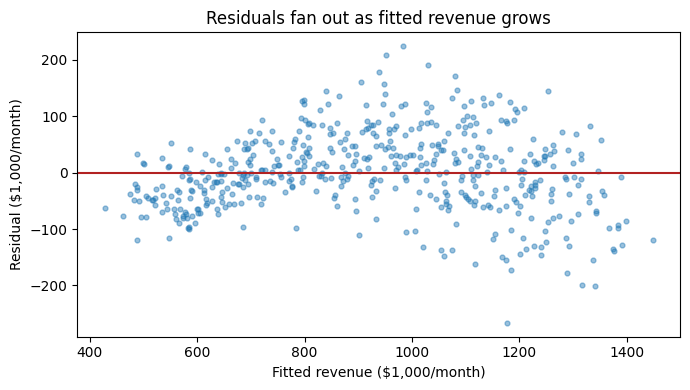

In [39]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(all_fit.fittedvalues, residual, s=12, alpha=0.45)
ax.axhline(0, color='firebrick')
ax.set(xlabel='Fitted revenue ($1,000/month)', ylabel='Residual ($1,000/month)',
       title='Residuals fan out as fitted revenue grows')
plt.tight_layout(); plt.show()

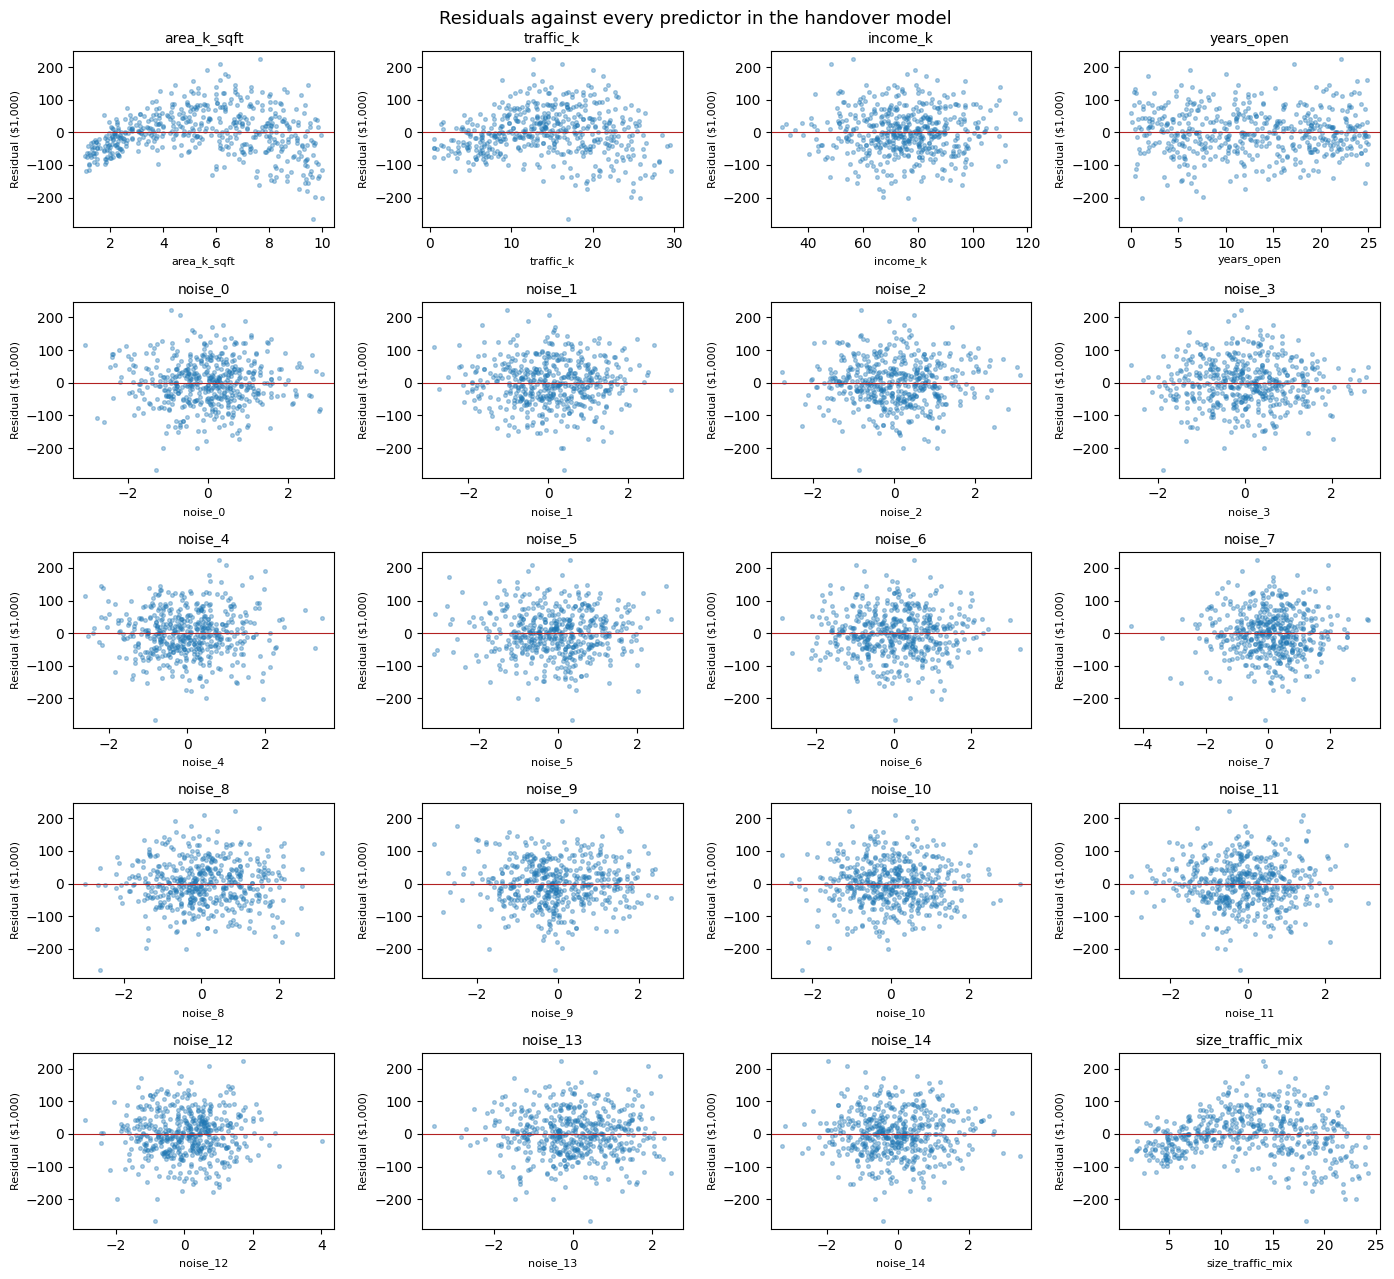

In [40]:
fig, axes = plt.subplots(5, 4, figsize=(14, 13))
for ax, col in zip(axes.flat, stores.columns):
    ax.scatter(stores[col], residual, s=7, alpha=0.35)
    ax.axhline(0, color='firebrick', linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel('Residual ($1,000)', fontsize=8)
fig.suptitle('Residuals against every predictor in the handover model', fontsize=13)
plt.tight_layout(); plt.show()

The residual plot fans out as revenue increases. The standard deviation of the residuals for the top fifth of stores is 2.26 times that of the bottom fifth so the assumption of constant variance is violated. On its own that varying spread would leave the OLS coefficients unbiased but the usual standard errors would be wrong. HC3 will fix the standard errors without altering the coefficients. There's also a curve in the residuals by floor area. There's revenue generated via a -5.2*area^2 term which the handover model omits. As such the area coefficients in HC3 are estimating the wrong marginal relationship and the forecasts will be biased by store size, since HC3 can't fix that problem; both the classical and the robust standard errors still relate to the wrong linear equation.

### Step 2.2: The over-forecast on big stores (15 pts)

In [41]:
test_error = y_test - test_pred
test_group = pd.qcut(X_test['area_k_sqft'], 5,
                     labels=['smallest', '2', '3', '4', 'largest'])
by_size = pd.DataFrame({'actual': y_test, 'error': test_error,
                        'size_group': test_group}).groupby('size_group', observed=True).agg(
                            mean_actual=('actual', 'mean'), mean_error=('error', 'mean'))
by_size['error_pct'] = 100 * by_size['mean_error'] / by_size['mean_actual']
display(by_size.round(2))

,mean_actual,mean_error,error_pct
size_group,,,
smallest,554.00,-31.41,-5.67
2,805.67,32.47,4.03
3,971.71,61.78,6.36
4,1111.44,10.98,0.99
largest,1247.75,-23.90,-1.92


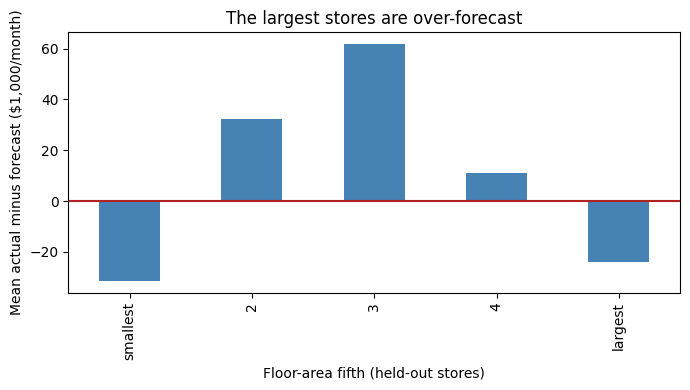

In [42]:
fig, ax = plt.subplots(figsize=(7, 4))
by_size['mean_error'].plot.bar(ax=ax, color='steelblue')
ax.axhline(0, color='firebrick')
ax.set(xlabel='Floor-area fifth (held-out stores)', ylabel='Mean actual minus forecast ($1,000/month)',
       title='The largest stores are over-forecast')
plt.tight_layout(); plt.show()

In [43]:
X_vif = sm.add_constant(stores)
vifs = pd.Series({col: variance_inflation_factor(X_vif.to_numpy(), i)
                  for i, col in enumerate(X_vif.columns) if col != 'const'}, name='VIF')
display(vifs.sort_values(ascending=False).round(1).to_frame())
without_mix = sm.OLS(revenue, sm.add_constant(stores.drop(columns='size_traffic_mix'))).fit()
print(f'All-data R² change from removing mix: {all_fit.rsquared - without_mix.rsquared:.6f}')
print(f'Area coefficient SE with/without mix: {all_fit.bse["area_k_sqft"]:.2f} / {without_mix.bse["area_k_sqft"]:.2f}')

,VIF
size_traffic_mix,3125.7
traffic_k,1042.7
area_k_sqft,644.5
noise_13,1.1
noise_14,1.1
noise_3,1.1
noise_5,1.1
noise_9,1.0
years_open,1.0
noise_4,1.0


All-data R² change from removing mix: 0.000113
Area coefficient SE with/without mix: 31.32 / 2.71


Of the held-out stores, the largest fifth by floor area are over forecasted by an average of $23.9k per month (1.92% of their mean actual revenue). Their actual minus forecast is negative whereas the middle groups have positive errors. That pattern is consistent with a straight line model of revenue growth which slows as the stores get bigger. The overall R² masks where the forecast is wrong.

The size_traffic_mix column has a VIF of approximately 3,126 as it is effectively duplicating the information in area and traffic,which both have very high VIFs. With that column in the model the standard error on the area coefficient is 31.32k, without it it's 2.71k. The in-sample R² is only changed by about 0.00011 by removing the column. A high VIF makes it difficult to pin down the individual coefficients, but it doesn't in itself cause the size related over-forecast or necessarily lead to worse forecasts. The forecasts could still be unstable for new combinations of area and traffic so I wouldn't just drop a predictor on the basis of VIF.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

,model,predictors,train_MSE,held_out_MSE
0,area only,1,8799.0,7783.9
1,area + traffic,2,5783.1,4895.0
2,four useful inputs,4,4854.9,5444.8
3,four + area squared,5,3553.9,3882.1
4,all original + area squared,21,3472.3,4075.1
5,add interactions,25,3437.6,4060.8
6,add more polynomials,29,3411.8,3974.1
7,add squared noise,44,3251.0,4227.8


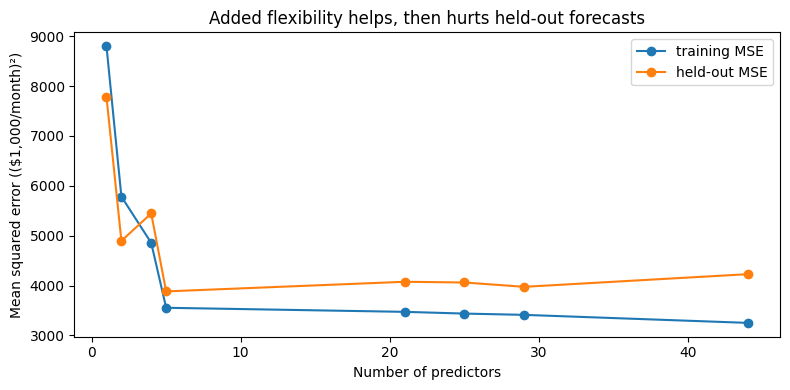

Lowest held-out error: four + area squared


In [44]:
features = stores.copy()
features['area_sq'] = area**2
features['area_x_traffic'] = area * traffic
features['traffic_sq'] = traffic**2
features['area_x_income'] = area * income
features['area_x_years'] = area * years
features['area_cu'] = area**3
features['traffic_cu'] = traffic**3
features['income_sq'] = income**2
features['years_sq'] = years**2
for j in range(15):
    features[f'noise_sq_{j}'] = stores[f'noise_{j}']**2

core = ['area_k_sqft', 'traffic_k', 'income_k', 'years_open']
candidate_names = ['area only', 'area + traffic', 'four useful inputs',
                   'four + area squared', 'all original + area squared',
                   'add interactions', 'add more polynomials', 'add squared noise']
candidates = [
    core[:1], core[:2], core,
    core + ['area_sq'],
    list(stores.columns) + ['area_sq'],
    list(stores.columns) + ['area_sq', 'area_x_traffic', 'traffic_sq',
                            'area_x_income', 'area_x_years'],
    list(stores.columns) + ['area_sq', 'area_x_traffic', 'traffic_sq',
                            'area_x_income', 'area_x_years', 'area_cu',
                            'traffic_cu', 'income_sq', 'years_sq'],
    list(features.columns)
]

train_mse, test_mse = [], []
for cols in candidates:
    a, b, c, d = train_test_split(features[cols], revenue,
                                  test_size=0.30, random_state=1)
    fit = sm.OLS(c, sm.add_constant(a)).fit()
    train_mse.append(np.mean((c - fit.predict(sm.add_constant(a)))**2))
    test_mse.append(np.mean((d - fit.predict(sm.add_constant(b)))**2))
sweep = pd.DataFrame({'model': candidate_names, 'predictors': [len(c) for c in candidates],
                      'train_MSE': train_mse, 'held_out_MSE': test_mse})
display(sweep.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep['predictors'], sweep['train_MSE'], marker='o', label='training MSE')
ax.plot(sweep['predictors'], sweep['held_out_MSE'], marker='o', label='held-out MSE')
ax.set(xlabel='Number of predictors', ylabel='Mean squared error (($1,000/month)²)',
       title='Added flexibility helps, then hurts held-out forecasts')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Lowest held-out error: {candidate_names[int(np.argmin(test_mse))]}')

On the held out stores MSE goes from around 7,784 with just area, down to 3,882 ($1,000) ^2 with the four useful predictors and area squared. It then goes up to about 4,228 for the most complex model, even as the training MSE continues to fall. The simpler models have more bias as they're missing the useful predictors and the curve in floor area. The later models are picking up on random patterns in the training stores which is adding variance. That's the pattern we're seeing there. I use cross validation to pick my final model.



### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [45]:
def fold_errors(x, y, cols, folds):
    """Held-out MSE for one candidate in each fold."""
    errors = []
    for train, test in folds.split(x):
        fit = sm.OLS(y[train], sm.add_constant(x.iloc[train][cols])).fit()
        forecast = fit.predict(sm.add_constant(x.iloc[test][cols]))
        errors.append(np.mean((y[test] - forecast)**2))
    return np.array(errors)


cv_folds = KFold(n_splits=5, shuffle=True, random_state=0)
cv_mse = [fold_errors(features, revenue, cols, cv_folds).mean()
          for cols in candidates]
best = int(np.argmin(cv_mse))
print(f'CV selection: {candidate_names[best]}, mean MSE {cv_mse[best]:.1f}')


outer_folds = KFold(n_splits=5, shuffle=True, random_state=2)
outer_errors, chosen = [], []
for train, test in outer_folds.split(features):
    inner_folds = KFold(n_splits=5, shuffle=True, random_state=1)
    inner_mse = [fold_errors(features.iloc[train], revenue[train], cols, inner_folds).mean()
                 for cols in candidates]
    choice = int(np.argmin(inner_mse))
    chosen.append(candidate_names[choice])
    fit = sm.OLS(revenue[train],
                 sm.add_constant(features.iloc[train][candidates[choice]])).fit()
    forecast = fit.predict(sm.add_constant(features.iloc[test][candidates[choice]]))
    outer_errors.append(np.mean((revenue[test] - forecast)**2))

nested_mse = np.mean(outer_errors)
margin = 2 * np.std(outer_errors, ddof=1) / np.sqrt(5)
print('Outer-fold choices:', chosen)
print('Outer-fold MSEs:', np.round(outer_errors, 1))
print(f'Nested MSE: {nested_mse:.1f}; rough mean-error interval: '
      f'{nested_mse-margin:.1f} to {nested_mse+margin:.1f} ($1,000)²')
print(f'Nested RMSE: ${np.sqrt(nested_mse):.1f}k per store-month')

final_features = candidates[best]
final_fit = sm.OLS(revenue, sm.add_constant(features[final_features])).fit()
print('Final model predictors:', final_features)
display(final_fit.params.round(3).to_frame('coefficient'))

CV selection: four + area squared, mean MSE 3760.3
Outer-fold choices: ['four + area squared', 'four + area squared', 'four + area squared', 'four + area squared', 'four + area squared']
Outer-fold MSEs: [3777.4 3691.6 5266.2 2456.3 3652.4]
Nested MSE: 3768.8; rough mean-error interval: 2876.1 to 4661.4 ($1,000)²
Nested RMSE: $61.4k per store-month
Final model predictors: ['area_k_sqft', 'traffic_k', 'income_k', 'years_open', 'area_sq']


,coefficient
const,117.167
area_k_sqft,121.382
traffic_k,18.219
income_k,1.270
years_open,1.491
area_sq,-6.392


I used 5-fold CV to select the model (area, traffic, income, years open and area squared). The MSE came in at 3,760 (1,000)². That number is probably a bit low as I used the same CV scores to select the model. I then ran nested CV, selecting a model within each outer training fold and then testing it on the held out fold. All five of the outer folds selected the same model. The average outer fold MSE was 3,769 (1,000)² or $61.4k RMSE per store month. The outer fold mean ± 2 x fold SD / √sqrt (5) gives a rough range of 2,876 to 4,661 (1,000)² for the average MSE. However, it donesn't say anything about the error for a particular store and doesn't guarantee anything for next month.

final_fit is then used to refit the model on all 500 stores. For a new store supply area, supply area, traffic, income and years open; calculate area_sq = area_k_sqft**2; then use final_fit.predict(sm.add_constant(new_data[final_features], has_constant='add')). The CV estimate is of course for stores drawn from the same simulated process. There is no actual June/July records and no change over time in this data so a check of the real post-July errors and next month accuracy would require a chronological holdout and another look at bias in the large stores.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

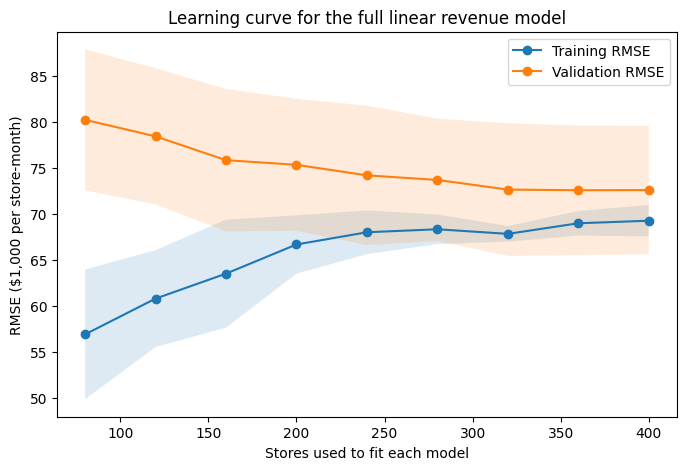

At 400 training stores: training RMSE $69.24k, validation RMSE $72.58k
Final gap: $3.34k
Full linear model CV RMSE: $72.85k
With area squared CV RMSE: $62.36k


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, learning_curve, cross_val_score

X, y = stores, revenue
folds = KFold(n_splits=5, shuffle=True, random_state=42)

sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y,
    train_sizes=np.linspace(0.2, 1.0, 9),
    cv=folds,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42
)

# Convert each fold's score to RMSE, in $1,000 per store-month.
train_rmse = np.sqrt(-train_scores)
valid_rmse = np.sqrt(-valid_scores)
train_mean, valid_mean = train_rmse.mean(axis=1), valid_rmse.mean(axis=1)
train_sd = train_rmse.std(axis=1, ddof=1)
valid_sd = valid_rmse.std(axis=1, ddof=1)

plt.figure(figsize=(8, 5))
plt.plot(sizes, train_mean, marker="o", label="Training RMSE")
plt.plot(sizes, valid_mean, marker="o", label="Validation RMSE")
plt.fill_between(sizes, train_mean-train_sd, train_mean+train_sd, alpha=0.15)
plt.fill_between(sizes, valid_mean-valid_sd, valid_mean+valid_sd, alpha=0.15)
plt.xlabel("Stores used to fit each model")
plt.ylabel("RMSE ($1,000 per store-month)")
plt.title("Learning curve for the full linear revenue model")
plt.legend()
plt.show()

# GAP: A large gap at the right suggests high variance; more stores may help.
# LEVEL: If both curves level off at high error relative to a better model,
# the current model has high bias; more of the same data is unlikely to help much.

print(f"At {sizes[-1]} training stores: training RMSE ${train_mean[-1]:.2f}k, "
      f"validation RMSE ${valid_mean[-1]:.2f}k")
print(f"Final gap: ${valid_mean[-1] - train_mean[-1]:.2f}k")

# Compare with the same predictors plus the missing area-squared term.
X_curved = X.copy()
X_curved["area_sq"] = X_curved["area_k_sqft"]**2
base_rmse = np.sqrt(-cross_val_score(
    LinearRegression(), X, y, cv=folds, scoring="neg_mean_squared_error"
).mean())
curved_rmse = np.sqrt(-cross_val_score(
    LinearRegression(), X_curved, y, cv=folds, scoring="neg_mean_squared_error"
).mean())
print(f"Full linear model CV RMSE: ${base_rmse:.2f}k")
print(f"With area squared CV RMSE: ${curved_rmse:.2f}k")

The learning curve supports my Phase 3 decision to go with a quadratic model. At 400 training stores we have a training RMSE of 69.24k and a validation RMSE of 72.58k with very little room for improvement in the validation curve. Area squared does a very good job of reducing the five fold CV RMSE (from 72.85k to 62.36k). That clearly points to the missing floor area curve as the primary deficiency in the inherited model. Phase 3 also demonstrated that the held-out error went up when we added a lot of extra terms. The learning curve only shows a small training/validation gap as it keeps the original linear model fixed and just adds stores. Phase 3 is the one that changes the complexity of the model. The extra terms are overfitting and the original model is simply not capturing the curve.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [50]:
X = np.random.default_rng(2026).normal(size=(N_STORES, 300))
y = revenue
print(f'{X.shape[0]} stores and {X.shape[1]} pure-noise predictors')

500 stores and 300 pure-noise predictors


In [49]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.92


In [51]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectKBest(f_regression, k=20)),
    ('ols', LinearRegression())
])
honest_scores = cross_val_score(pipe, X, y, cv=5, scoring='r2')
print(f'Leaky fold R²: {np.round(scores, 3)}')
print(f'Pipeline fold R²: {np.round(honest_scores, 3)}')
print(f'Leaky mean R²: {scores.mean():.3f}')
print(f'Pipeline mean R²: {honest_scores.mean():.3f}')
print(f'Inflation: {scores.mean() - honest_scores.mean():.3f}')

Leaky fold R²: [0.914 0.922 0.934 0.904 0.914]
Pipeline fold R²: [-0.224 -0.094 -0.058 -0.209 -0.174]
Leaky mean R²: 0.918
Pipeline mean R²: -0.152
Inflation: 1.070


The leak occurs when SelectKBest(...).fit_transform(X_scaled, y) selects 20 columns based on revenue from all 500 stores. CV then scores the model on the stores whose revenue was used in the selection of those columns. Even with 300 pure noise predictors the leaked cell reports an R² of 0.09. If we fit the scaling and selection separately within each training fold, the mean R² is −0.152, a difference of 0.241. A negative R² on the held out data means the model is performing worse than the held out mean.

The analyst also fitted the scaler prior to cross-validation so I've moved it into the pipeline. For unregularised linear regression with an intercept, rescaling on its own makes no difference to the prediction, the large inflation is due to the supervised column selection. The pipeline is testing the steps that would be run for a new store. That's why the 'validated' score in the copied cell is so unreliable. To work out how much of the actual post-July error was due to leakage I'd need the original store and month records.


### Task 4.3: The handover note (3 pts)

The current model predicts a store's monthly revenue from floor area, footfall, local income, years open, and floor area squared. The floor area squared term is included to account for the fact that the rate of revenue growth tends to diminish as the store gets bigger. Nested CV on 500 simulated stores gives an RMSE of $61.4k per store-month. That's an estimate of the error for new stores drawn from the same simulated process, not the actual forecast error I will see for next month. I expect to see worse performance in two scenarios. Firstly, large stores have more variable revenue so their individual forecasts are less reliable and the inherited straight-line model also over-forecasts the largest stores. Secondly, forecasts will be poor if the situation changes over the course of the month. This dataset has no month-on-month history so it can't test for the post-July shift. The next step would be to build a store-by-month dataset from the actual records, include the relevant time effects and then evaluate the forecasts on later months held out in time. I will report the overall error and the large store bias separately before using the model to make any decisions.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:* GPT-6 Sol

*Prompt:* [Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 500 rows and
20 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my stores and revenue.
Plot both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.

*Reply:*

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, learning_curve, cross_val_score

X, y = stores, revenue
folds = KFold(n_splits=5, shuffle=True, random_state=42)

sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y,
    train_sizes=np.linspace(0.2, 1.0, 9),
    cv=folds,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42
)

# Convert each fold's score to RMSE, in $1,000 per store-month.
train_rmse = np.sqrt(-train_scores)
valid_rmse = np.sqrt(-valid_scores)
train_mean, valid_mean = train_rmse.mean(axis=1), valid_rmse.mean(axis=1)
train_sd = train_rmse.std(axis=1, ddof=1)
valid_sd = valid_rmse.std(axis=1, ddof=1)

plt.figure(figsize=(8, 5))
plt.plot(sizes, train_mean, marker="o", label="Training RMSE")
plt.plot(sizes, valid_mean, marker="o", label="Validation RMSE")
plt.fill_between(sizes, train_mean-train_sd, train_mean+train_sd, alpha=0.15)
plt.fill_between(sizes, valid_mean-valid_sd, valid_mean+valid_sd, alpha=0.15)
plt.xlabel("Stores used to fit each model")
plt.ylabel("RMSE ($1,000 per store-month)")
plt.title("Learning curve for the full linear revenue model")
plt.legend()
plt.show()

# GAP: A large gap at the right suggests high variance; more stores may help.
# LEVEL: If both curves level off at high error relative to a better model,
# the current model has high bias; more of the same data is unlikely to help much.

print(f"At {sizes[-1]} training stores: training RMSE ${train_mean[-1]:.2f}k, "
      f"validation RMSE ${valid_mean[-1]:.2f}k")
print(f"Final gap: ${valid_mean[-1] - train_mean[-1]:.2f}k")

# Compare with the same predictors plus the missing area-squared term.
X_curved = X.copy()
X_curved["area_sq"] = X_curved["area_k_sqft"]**2
base_rmse = np.sqrt(-cross_val_score(
    LinearRegression(), X, y, cv=folds, scoring="neg_mean_squared_error"
).mean())
curved_rmse = np.sqrt(-cross_val_score(
    LinearRegression(), X_curved, y, cv=folds, scoring="neg_mean_squared_error"
).mean())
print(f"Full linear model CV RMSE: ${base_rmse:.2f}k")
print(f"With area squared CV RMSE: ${curved_rmse:.2f}k")

On the notebook’s 500 simulated stores, the curves finish at $69.24k training RMSE and $72.58k validation RMSE. The gap is only $3.34k, and validation RMSE barely changes between 320 and 400 training stores. Adding area squared lowers five-fold CV RMSE from $72.85k to $62.36k. For this simulation, improving the model’s features looks more useful than collecting more similar stores. The shaded bands show one standard deviation across folds, not confidence intervals; this result does not establish the return for real production stores.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.